In [1]:
import os
import sys
root = os.path.abspath('..')
os.chdir(root)
sys.path.append(root)

import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
import scienceplots

from config import Config
from utils.available_resources_model import AvailableResourcesModel
from utils.vector_arima_simulator import VectorArimaSimulator, SimulatorConfig

plt.style.use(['science'])

config = Config()

In [2]:
df = pd.read_csv(
    os.path.join(config.data_dir, 'available_resources.csv'),
    parse_dates=['timestamp'],
).set_index('timestamp')

N = len(df)
t = np.arange(N)  # time axis in seconds

df.head(3)

,bandwidth_in,bandwidth_out,storage,memory,cpu
timestamp,,,,,
2025-10-23 15:10:06,9.304500e+08,9.227259e+08,2.750020e+11,3.591477e+09,989.9
2025-10-23 15:10:07,9.299396e+08,9.230137e+08,2.738388e+11,3.300011e+09,1007.1
2025-10-23 15:10:08,9.294292e+08,9.233015e+08,2.726755e+11,3.008545e+09,1024.3


In [ ]:
# LNCS single-column width: ~8.5 cm  (matches survival_functions.ipynb)
FIG_W = 8.5 / 2.54
FIG_H = 5.0 / 2.54


def save_fig(filename):
    figures_dir = os.path.join(config.resource_dir, 'figures')
    os.makedirs(figures_dir, exist_ok=True)
    plt.savefig(os.path.join(figures_dir, filename), bbox_inches='tight')


def plot_series(series, ylabel, color='C0', filename=None):
    """Plot a 1-D time series against sample index."""
    fig, ax = plt.subplots(figsize=(FIG_W, FIG_H))
    ax.plot(np.arange(len(series)), series, color=color, linewidth=0.6)
    ax.set_xlabel('Time (s)')
    ax.set_ylabel(ylabel)
    ax.set_xlim(0, len(series) - 1)
    fig.tight_layout()
    if filename:
        save_fig(filename)
    plt.show()


def load_simulator(model_filename):
    """Load an AvailableResourcesModel and return a ready (simulator, config) pair."""
    model = AvailableResourcesModel.load(
        os.path.join(config.resource_dir, 'models', model_filename)
    )
    sim = VectorArimaSimulator(params=model.model_param_dict, n_series=1)
    sim_config = SimulatorConfig(
        n_series=1,
        mean=torch.tensor([model.original_mean]),
        std=torch.tensor([model.original_std]),
        power_transform_lambda=np.array([model.power_transform_lambda]),
        min=torch.tensor([0.]),
        max=torch.tensor([model.original_max]),
    )
    return sim, sim_config


def simulate(model_filename, n):
    """Simulate *n* steps from the saved model; return a 1-D numpy array."""
    sim, sim_config = load_simulator(model_filename)
    return sim.simulate(n_simulations=n, config=sim_config)[0].numpy()

### Bandwidth in

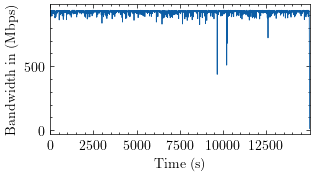

In [4]:
plot_series(df['bandwidth_in'] / 1e6, ylabel='Bandwidth in (Mbps)',
            filename='available_bandwidth_in_original.pdf')

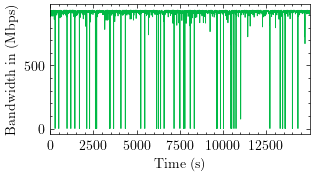

In [5]:
plot_series(simulate('available_bandwidth_in_model.json', N) / 1e6,
            ylabel='Bandwidth in (Mbps)', color='C1',
            filename='available_bandwidth_in_simulated.pdf')

### Bandwidth out

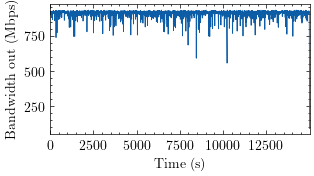

In [6]:
plot_series(df['bandwidth_out'] / 1e6, ylabel='Bandwidth out (Mbps)',
            filename='available_bandwidth_out_original.pdf')

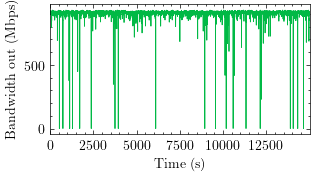

In [7]:
plot_series(simulate('available_bandwidth_out_model.json', N) / 1e6,
            ylabel='Bandwidth out (Mbps)', color='C1',
            filename='available_bandwidth_out_simulated.pdf')

### Storage

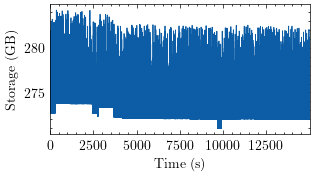

In [8]:
plot_series(df['storage'] / 1e9, ylabel='Storage (GB)',
            filename='available_storage_original.pdf')

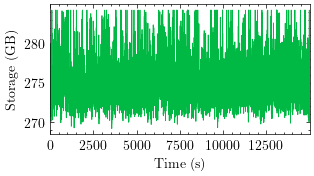

In [9]:
plot_series(simulate('available_storage_model.json', N) / 1e9,
            ylabel='Storage (GB)', color='C1',
            filename='available_storage_simulated.pdf')

### Memory

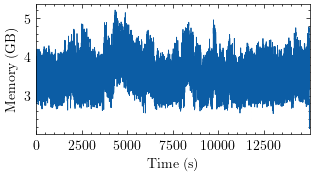

In [10]:
plot_series(df['memory'] / 1e9, ylabel='Memory (GB)',
            filename='available_memory_original.pdf')

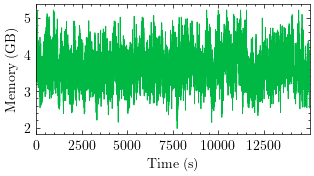

In [11]:
plot_series(simulate('available_memory_model.json', N) / 1e9,
            ylabel='Memory (GB)', color='C1',
            filename='available_memory_simulated.pdf')

### CPU

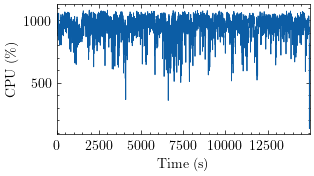

In [14]:
plot_series(df['cpu'], ylabel='CPU (\%)',
            filename='available_cpu_original.pdf')


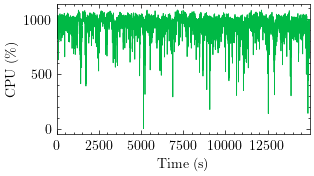

In [13]:
plot_series(simulate('available_cpu_model.json', N),
            ylabel='CPU (\%)', color='C1',
            filename='available_cpu_simulated.pdf')